
# Phase 2: Technical Application — Baseline Implementation

## Research Paper
Early prediction of gallstone disease with a machine learning-based method from bioimpedance and laboratory data (Esen et al., 2024).

## Objective
The objective of Phase 2 is to implement and evaluate machine learning models for gallstone disease classification.

Logistic Regression will be used as the primary baseline model. Eight additional algorithms will be implemented for comparison.

The experiments will also investigate the effects of feature scaling and ANOVA feature selection, addressing methodological concerns identified in Phase 1.



## 1. Dataset Loading and Initial Inspection

Before training the machine learning models, the dataset is loaded and examined to verify its structure, feature names, target variable, missing values and duplicate records.

This ensures that the dataset is suitable for the classification task.


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RANDOM_STATE = 42


In [ ]:

df = pd.read_csv("dataset-uci.csv")

print("Dataset Shape:", df.shape)

df.head()


Dataset Shape: (319, 39)


,Gallstone Status,Age,Gender,Comorbidity,Coronary Artery Disease (CAD),Hypothyroidism,Hyperlipidemia,Diabetes Mellitus (DM),Height,Weight,...,High Density Lipoprotein (HDL),Triglyceride,Aspartat Aminotransferaz (AST),Alanin Aminotransferaz (ALT),Alkaline Phosphatase (ALP),Creatinine,Glomerular Filtration Rate (GFR),C-Reactive Protein (CRP),Hemoglobin (HGB),Vitamin D
0,0,50,0,0,0,0,0,0,185,92.8,...,40.0,134.0,20.0,22.0,87.0,0.82,112.47,0.0,16.0,33.0
1,0,47,0,1,0,0,0,0,176,94.5,...,43.0,103.0,14.0,13.0,46.0,0.87,107.10,0.0,14.4,25.0
2,0,61,0,0,0,0,0,0,171,91.1,...,43.0,69.0,18.0,14.0,66.0,1.25,65.51,0.0,16.2,30.2
3,0,41,0,0,0,0,0,0,168,67.7,...,59.0,53.0,20.0,12.0,34.0,1.02,94.10,0.0,15.4,35.4
4,0,42,0,0,0,0,0,0,178,89.6,...,30.0,326.0,27.0,54.0,71.0,0.82,112.47,0.0,16.8,40.6


In [3]:

print("Column Names:")

for index, column in enumerate(df.columns, start=1):
    print(index, column)


Column Names:
1 Gallstone Status
2 Age
3 Gender
4 Comorbidity
5 Coronary Artery Disease (CAD)
6 Hypothyroidism
7 Hyperlipidemia
8 Diabetes Mellitus (DM)
9 Height
10 Weight
11 Body Mass Index (BMI)
12 Total Body Water (TBW)
13 Extracellular Water (ECW)
14 Intracellular Water (ICW)
15 Extracellular Fluid/Total Body Water (ECF/TBW)
16 Total Body Fat Ratio (TBFR) (%)
17 Lean Mass (LM) (%)
18 Body Protein Content (Protein) (%)
19 Visceral Fat Rating (VFR)
20 Bone Mass (BM)
21 Muscle Mass (MM)
22 Obesity (%)
23 Total Fat Content (TFC)
24 Visceral Fat Area (VFA)
25 Visceral Muscle Area (VMA) (Kg)
26 Hepatic Fat Accumulation (HFA)
27 Glucose
28 Total Cholesterol (TC)
29 Low Density Lipoprotein (LDL)
30 High Density Lipoprotein (HDL)
31 Triglyceride
32 Aspartat Aminotransferaz (AST)
33 Alanin Aminotransferaz (ALT)
34 Alkaline Phosphatase (ALP)
35 Creatinine
36 Glomerular Filtration Rate (GFR)
37 C-Reactive Protein (CRP)
38 Hemoglobin (HGB)
39 Vitamin D


In [4]:

print("Missing Values in Each Column:")

print(df.isnull().sum())

print("\nTotal Missing Values:", df.isnull().sum().sum())


Missing Values in Each Column:
Gallstone Status                                  0
Age                                               0
Gender                                            0
Comorbidity                                       0
Coronary Artery Disease (CAD)                     0
Hypothyroidism                                    0
Hyperlipidemia                                    0
Diabetes Mellitus (DM)                            0
Height                                            0
Weight                                            0
Body Mass Index (BMI)                             0
Total Body Water (TBW)                            0
Extracellular Water (ECW)                         0
Intracellular Water (ICW)                         0
Extracellular Fluid/Total Body Water (ECF/TBW)    0
Total Body Fat Ratio (TBFR) (%)                   0
Lean Mass (LM) (%)                                0
Body Protein Content (Protein) (%)                0
Visceral Fat Rating (VFR)        

In [5]:

print("Duplicate Records:", df.duplicated().sum())


Duplicate Records: 0


In [6]:

target_column = "Gallstone Status"

print(df[target_column].value_counts().sort_index())


Gallstone Status
0    161
1    158
Name: count, dtype: int64


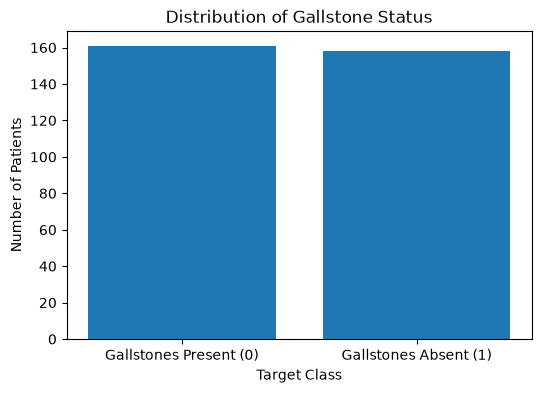

In [8]:

class_counts = df["Gallstone Status"].value_counts().sort_index()

plt.figure(figsize=(6, 4))

plt.bar(
    ["Gallstones Present (0)", "Gallstones Absent (1)"],
    class_counts.values
)

plt.title("Distribution of Gallstone Status")
plt.xlabel("Target Class")
plt.ylabel("Number of Patients")

plt.show()



## 2. Separating Input Features and Target Variable

The dataset is divided into input features (X) and the target variable (y).

X contains the 38 clinical, laboratory, demographic and bioimpedance features used to predict gallstone disease.

The target variable y represents Gallstone Status, where 0 indicates gallstones present and 1 indicates gallstones absent.

Separating X and y allows the machine learning algorithms to learn the relationship between patient measurements and gallstone status.


In [9]:

# Separate input features and target variable

X = df.drop(columns=["Gallstone Status"])

y = df["Gallstone Status"]

print("Input Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nInput Feature Names:")
print(X.columns.tolist())

print("\nTarget Distribution:")
print(y.value_counts().sort_index())


Input Features Shape: (319, 38)
Target Shape: (319,)

Input Feature Names:
['Age', 'Gender', 'Comorbidity', 'Coronary Artery Disease (CAD)', 'Hypothyroidism', 'Hyperlipidemia', 'Diabetes Mellitus (DM)', 'Height', 'Weight', 'Body Mass Index (BMI)', 'Total Body Water (TBW)', 'Extracellular Water (ECW)', 'Intracellular Water (ICW)', 'Extracellular Fluid/Total Body Water (ECF/TBW)', 'Total Body Fat Ratio (TBFR) (%)', 'Lean Mass (LM) (%)', 'Body Protein Content (Protein) (%)', 'Visceral Fat Rating (VFR)', 'Bone Mass (BM)', 'Muscle Mass (MM)', 'Obesity (%)', 'Total Fat Content (TFC)', 'Visceral Fat Area (VFA)', 'Visceral Muscle Area (VMA) (Kg)', 'Hepatic Fat Accumulation (HFA)', 'Glucose', 'Total Cholesterol (TC)', 'Low Density Lipoprotein (LDL)', 'High Density Lipoprotein (HDL)', 'Triglyceride', 'Aspartat Aminotransferaz (AST)', 'Alanin Aminotransferaz (ALT)', 'Alkaline Phosphatase (ALP)', 'Creatinine', 'Glomerular Filtration Rate (GFR)', 'C-Reactive Protein (CRP)', 'Hemoglobin (HGB)', 'Vit


## 2.1 Stratified Train-Test Splitting

The dataset is divided into 70% training data and 30% testing data.

Stratified sampling is used to preserve the original proportions of patients with and without gallstones in both sets.

The training dataset is used for model development, feature selection and hyperparameter tuning.

The testing dataset is kept separate and used only for final model evaluation.

A fixed random state of 42 is used to make the split reproducible.


In [10]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)


Training Features: (223, 38)
Testing Features: (96, 38)
Training Target: (223,)
Testing Target: (96,)


In [11]:

print("Original Dataset:")
print(y.value_counts(normalize=True).sort_index() * 100)

print("\nTraining Dataset:")
print(y_train.value_counts(normalize=True).sort_index() * 100)

print("\nTesting Dataset:")
print(y_test.value_counts(normalize=True).sort_index() * 100)


Original Dataset:
Gallstone Status
0    50.470219
1    49.529781
Name: proportion, dtype: float64

Training Dataset:
Gallstone Status
0    50.672646
1    49.327354
Name: proportion, dtype: float64

Testing Dataset:
Gallstone Status
0    50.0
1    50.0
Name: proportion, dtype: float64



## 2.2 Preventing Data Leakage

In Phase 1, I identified that the research paper did not clearly explain the exact order of ANOVA feature selection and train-test splitting.

This is important because ANOVA uses the target labels to identify relevant input features.

If ANOVA is fitted before splitting the dataset, information from the test data can influence feature selection and may lead to overly optimistic evaluation results.

To reduce this risk, the dataset is split before supervised feature selection.

During model development, ANOVA will be included inside a machine learning pipeline and fitted separately within each training fold during cross-validation.

The independent test dataset will remain unused until final evaluation.


In [12]:

train_indices = set(X_train.index)
test_indices = set(X_test.index)

overlap = train_indices.intersection(test_indices)

print("Overlapping Row Indices:", len(overlap))

assert len(overlap) == 0, "Training and testing rows overlap!"


Overlapping Row Indices: 0



## 3. Logistic Regression Baseline Implementation

Logistic Regression is selected as the primary baseline model because gallstone disease classification is a supervised binary classification problem.

The model learns relationships between the 38 input features and Gallstone Status.

StandardScaler is applied to standardize the input features because the dataset contains measurements with different numerical scales.

A machine learning pipeline is used to ensure that preprocessing is fitted using only the training dataset.

The baseline model will be evaluated using accuracy, precision, recall, F1-score, specificity, ROC-AUC and a confusion matrix.


In [13]:

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.impute import SimpleImputer


In [14]:

lr_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=2000,
        random_state=RANDOM_STATE
    ))
])

print(lr_pipeline)


Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('model', LogisticRegression(max_iter=2000, random_state=42))])


In [15]:

lr_pipeline.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")


Logistic Regression model trained successfully!


In [16]:

y_pred = lr_pipeline.predict(X_test)

print("First 10 Predicted Values:")
print(y_pred[:10])

print("\nFirst 10 Actual Values:")
print(y_test.iloc[:10].values)


First 10 Predicted Values:
[1 1 0 1 0 1 1 1 0 0]

First 10 Actual Values:
[1 1 1 1 0 1 1 1 0 1]


In [17]:

y_prob = lr_pipeline.predict_proba(X_test)

print("Class Order:", lr_pipeline.classes_)

print("\nFirst 5 Probability Predictions:")
print(y_prob[:5])


Class Order: [0 1]

First 5 Probability Predictions:
[[0.03652327 0.96347673]
 [0.06626756 0.93373244]
 [0.61026094 0.38973906]
 [0.00413383 0.99586617]
 [0.98114921 0.01885079]]


In [18]:

disease_class_index = list(lr_pipeline.classes_).index(0)

y_prob_gallstones = y_prob[:, disease_class_index]

print("First 10 Gallstone Probabilities:")
print(y_prob_gallstones[:10])


First 10 Gallstone Probabilities:
[3.65232722e-02 6.62675611e-02 6.10260942e-01 4.13383119e-03
 9.81149209e-01 6.00943867e-02 4.23426134e-02 1.03524070e-04
 8.58333088e-01 5.57817671e-01]



## 3.1 Baseline Model Evaluation

The Logistic Regression baseline is evaluated using several classification metrics.

Accuracy measures overall correct predictions.

Precision measures how many patients predicted to have gallstones actually have gallstones.

Recall (Sensitivity) measures how many patients with gallstones are correctly detected.

Specificity measures how many patients without gallstones are correctly identified.

F1-score combines precision and recall.

ROC-AUC evaluates the model's ability to distinguish patients with and without gallstones across different classification thresholds.

Gallstones present (class 0) is treated as the positive clinical condition throughout the evaluation.


In [19]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)


In [20]:

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", round(accuracy, 4))


Accuracy: 0.7812


In [21]:

precision = precision_score(
    y_test, y_pred,
    pos_label=0,
    zero_division=0
)

recall = recall_score(
    y_test, y_pred,
    pos_label=0,
    zero_division=0
)

f1 = f1_score(
    y_test, y_pred,
    pos_label=0,
    zero_division=0
)

print("Precision:", round(precision, 4))
print("Recall / Sensitivity:", round(recall, 4))
print("F1-score:", round(f1, 4))


Precision: 0.7647
Recall / Sensitivity: 0.8125
F1-score: 0.7879


In [22]:

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1]
)

print("Confusion Matrix:")
print(cm)


Confusion Matrix:
[[39  9]
 [12 36]]


In [23]:

TP = cm[0, 0]
FN = cm[0, 1]
FP = cm[1, 0]
TN = cm[1, 1]

print("True Positive:", TP)
print("False Negative:", FN)
print("False Positive:", FP)
print("True Negative:", TN)


True Positive: 39
False Negative: 9
False Positive: 12
True Negative: 36


In [24]:

specificity = TN / (TN + FP)

print("Specificity:", round(specificity, 4))


Specificity: 0.75


In [25]:

roc_auc = roc_auc_score(
    (y_test == 0).astype(int),
    y_prob_gallstones
)

print("ROC-AUC:", round(roc_auc, 4))


ROC-AUC: 0.8841


In [27]:
baseline_results = pd.DataFrame({
    "Model": ["Logistic Regression"],
    "Accuracy": [accuracy],
    "Precision": [precision],
    "Recall": [recall],
    "Specificity": [specificity],
    "F1-score": [f1],
    "ROC-AUC": [roc_auc]
})

baseline_results.round(4)


,Model,Accuracy,Precision,Recall,Specificity,F1-score,ROC-AUC
0,Logistic Regression,0.7812,0.7647,0.8125,0.75,0.7879,0.8841


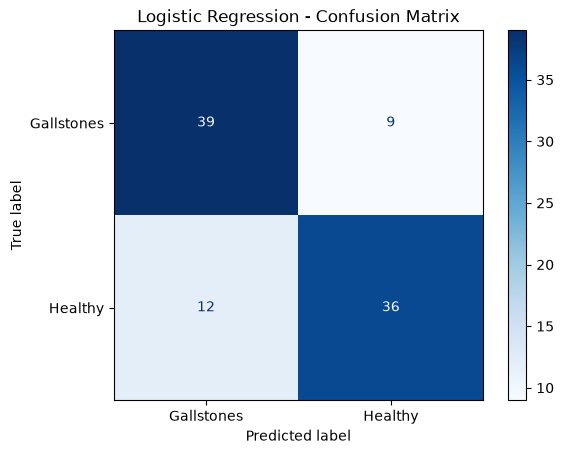

In [28]:

import matplotlib.pyplot as plt

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Gallstones", "Healthy"]
).plot(cmap="Blues")

plt.title("Logistic Regression - Confusion Matrix")
plt.show()


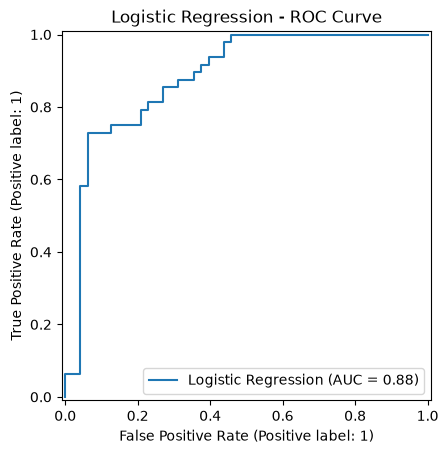

In [29]:

from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_predictions(
    (y_test == 0).astype(int),
    y_prob_gallstones,
    name="Logistic Regression"
)

plt.title("Logistic Regression - ROC Curve")
plt.show()



## 4. ANOVA Feature Selection

ANOVA (Analysis of Variance) is used to evaluate the relationship between each input feature and Gallstone Status.

The ANOVA F-test compares differences between the gallstone and healthy groups relative to variation within each group.

Features with higher F-scores show stronger individual statistical associations with the target variable.

This experiment investigates whether selecting 32 features improves Logistic Regression performance compared with the original baseline using all 38 features.

To prevent data leakage, ANOVA feature selection is fitted only using training data. During cross-validation, feature selection is performed separately within each training fold.


In [30]:

from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import make_scorer, roc_auc_score


In [31]:

cv = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=RANDOM_STATE
)

print("10-Fold Stratified Cross-Validation Created")


10-Fold Stratified Cross-Validation Created


In [32]:

anova_lr_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("anova", SelectKBest(
        score_func=f_classif,
        k=32
    )),
    ("model", LogisticRegression(
        max_iter=2000,
        random_state=RANDOM_STATE
    ))
])

print(anova_lr_pipeline)


Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()), ('anova', SelectKBest(k=32)),
                ('model', LogisticRegression(max_iter=2000, random_state=42))])


In [33]:

def gallstone_auc(estimator, X_valid, y_valid):

    # Find probability column for gallstones present
    class_index = list(estimator.classes_).index(0)

    probabilities = estimator.predict_proba(
        X_valid
    )[:, class_index]

    # Convert gallstones present to positive class
    y_binary = (np.asarray(y_valid) == 0).astype(int)

    return roc_auc_score(y_binary, probabilities)


In [34]:

anova_cv_scores = cross_validate(
    anova_lr_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "roc_auc": gallstone_auc
    },
    n_jobs=-1
)

print(
    "Mean CV Accuracy:",
    round(anova_cv_scores["test_accuracy"].mean(), 4)
)

print(
    "Mean CV ROC-AUC:",
    round(anova_cv_scores["test_roc_auc"].mean(), 4)
)

print(
    "CV ROC-AUC Standard Deviation:",
    round(anova_cv_scores["test_roc_auc"].std(), 4)
)


Mean CV Accuracy: 0.7269
Mean CV ROC-AUC: 0.8074
CV ROC-AUC Standard Deviation: 0.1024


In [37]:

baseline_cv_scores = cross_validate(
    lr_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "roc_auc": gallstone_auc
    },
    n_jobs=-1
)

comparison_cv = pd.DataFrame({
    "Model": [
        "Logistic Regression - 38 Features",
        "Logistic Regression - ANOVA 32 Features"
    ],
    "Mean CV Accuracy": [
        baseline_cv_scores["test_accuracy"].mean(),
        anova_cv_scores["test_accuracy"].mean()
    ],
    "Mean CV ROC-AUC": [
        baseline_cv_scores["test_roc_auc"].mean(),
        anova_cv_scores["test_roc_auc"].mean()
    ],
    "CV ROC-AUC SD": [
        baseline_cv_scores["test_roc_auc"].std(),
        anova_cv_scores["test_roc_auc"].std()
    ]
})

comparison_cv.round(4)


,Model,Mean CV Accuracy,Mean CV ROC-AUC,CV ROC-AUC SD
0,Logistic Regression - 38 Features,0.7449,0.8213,0.0984
1,Logistic Regression - ANOVA 32 Features,0.7269,0.8074,0.1024


In [38]:

anova_lr_pipeline.fit(X_train, y_train)

print("ANOVA Logistic Regression trained successfully!")


ANOVA Logistic Regression trained successfully!


In [39]:

selector = anova_lr_pipeline.named_steps["anova"]

selected_mask = selector.get_support()

selected_features = X_train.columns[selected_mask]

removed_features = X_train.columns[~selected_mask]

print("Number of Selected Features:", len(selected_features))

print("\nSelected Features:")
for feature in selected_features:
    print(feature)

print("\nRemoved Features:")
for feature in removed_features:
    print(feature)


Number of Selected Features: 32

Selected Features:
Gender
Coronary Artery Disease (CAD)
Hypothyroidism
Hyperlipidemia
Diabetes Mellitus (DM)
Height
Body Mass Index (BMI)
Total Body Water (TBW)
Extracellular Water (ECW)
Intracellular Water (ICW)
Extracellular Fluid/Total Body Water (ECF/TBW)
Total Body Fat Ratio (TBFR) (%)
Lean Mass (LM) (%)
Body Protein Content (Protein) (%)
Bone Mass (BM)
Muscle Mass (MM)
Obesity (%)
Total Fat Content (TFC)
Visceral Fat Area (VFA)
Visceral Muscle Area (VMA) (Kg)
Hepatic Fat Accumulation (HFA)
Total Cholesterol (TC)
Low Density Lipoprotein (LDL)
High Density Lipoprotein (HDL)
Triglyceride
Aspartat Aminotransferaz (AST)
Alanin Aminotransferaz (ALT)
Alkaline Phosphatase (ALP)
Creatinine
C-Reactive Protein (CRP)
Hemoglobin (HGB)
Vitamin D

Removed Features:
Age
Comorbidity
Weight
Visceral Fat Rating (VFR)
Glucose
Glomerular Filtration Rate (GFR)


In [ ]:

anova_feature_scores = pd.DataFrame({
    "Feature": X_train.columns,
    "F-Score": selector.scores_,
    "P-Value": selector.pvalues_,
    "Selected": selected_mask
})

anova_feature_scores = anova_feature_scores.sort_values(
    by="F-Score",
    ascending=False
)

anova_feature_scores


,Feature,F-Score,P-Value,Selected
37,Vitamin D,30.759890,8.299782e-08,True
35,C-Reactive Protein (CRP),17.219178,4.753280e-05,True
18,Bone Mass (BM),13.359681,3.212441e-04,True
15,Lean Mass (LM) (%),8.799408,3.344496e-03,True
11,Extracellular Water (ECW),8.694854,3.534022e-03,True
14,Total Body Fat Ratio (TBFR) (%),8.311681,4.327990e-03,True
30,Aspartat Aminotransferaz (AST),7.908454,5.363136e-03,True
5,Hyperlipidemia,6.460762,1.171322e-02,True
28,High Density Lipoprotein (HDL),5.824143,1.662289e-02,True
10,Total Body Water (TBW),4.642691,3.226743e-02,True


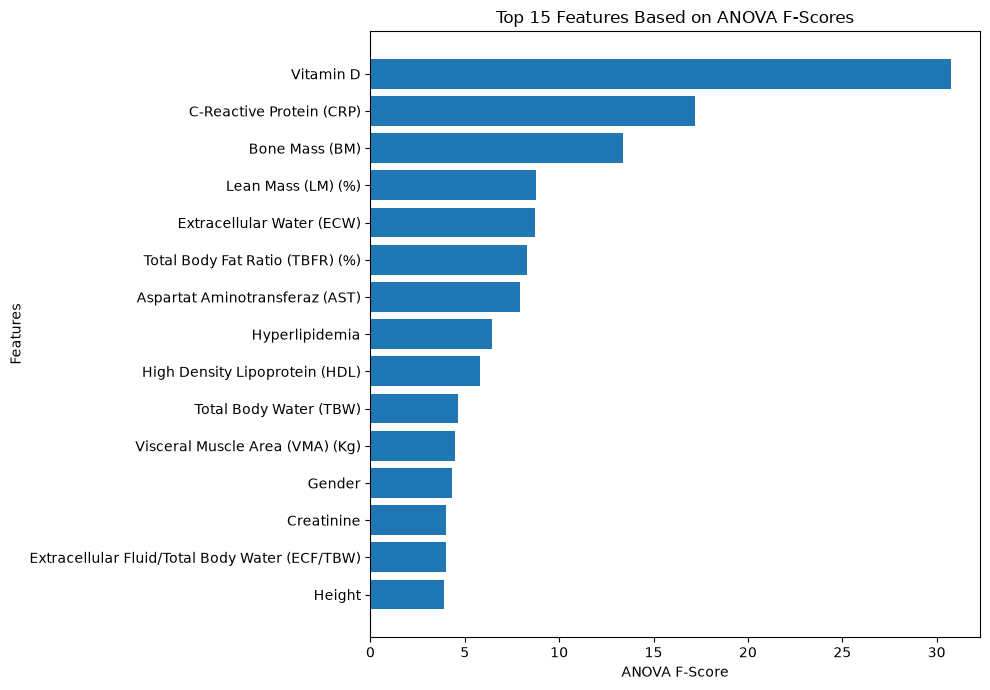

In [41]:

top_15 = anova_feature_scores.head(15)

plt.figure(figsize=(10, 7))

plt.barh(
    top_15["Feature"],
    top_15["F-Score"]
)

plt.xlabel("ANOVA F-Score")
plt.ylabel("Features")
plt.title("Top 15 Features Based on ANOVA F-Scores")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()


In [42]:

anova_y_pred = anova_lr_pipeline.predict(X_test)

class_index = list(anova_lr_pipeline.classes_).index(0)

anova_y_prob = anova_lr_pipeline.predict_proba(
    X_test
)[:, class_index]


In [ ]:

anova_cm = confusion_matrix(
    y_test,
    anova_y_pred,
    labels=[0, 1]
)

TP, FN = anova_cm[0]
FP, TN = anova_cm[1]

anova_results = {
    "Accuracy": accuracy_score(y_test, anova_y_pred),
    "Precision": precision_score(
        y_test, anova_y_pred,
        pos_label=0, zero_division=0
    ),
    "Recall": recall_score(
        y_test, anova_y_pred,
        pos_label=0, zero_division=0
    ),
    "Specificity": TN / (TN + FP),
    "F1-score": f1_score(
        y_test, anova_y_pred,
        pos_label=0, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        (y_test == 0).astype(int),
        anova_y_prob
    )
}

pd.DataFrame([anova_results]).round(4)


,Accuracy,Precision,Recall,Specificity,F1-score,ROC-AUC
0,0.8229,0.8298,0.8125,0.8333,0.8211,0.8885


In [ ]:

baseline_row = baseline_results.copy()
baseline_row["Model"] = "LR - All 38 Features"

anova_row = pd.DataFrame([{
    "Model": "LR - ANOVA 32 Features",
    **anova_results
}])

final_comparison = pd.concat(
    [baseline_row, anova_row],
    ignore_index=True
)

final_comparison.round(4)


,Model,Accuracy,Precision,Recall,Specificity,F1-score,ROC-AUC
0,LR - All 38 Features,0.7812,0.7647,0.8125,0.7500,0.7879,0.8841
1,LR - ANOVA 32 Features,0.8229,0.8298,0.8125,0.8333,0.8211,0.8885


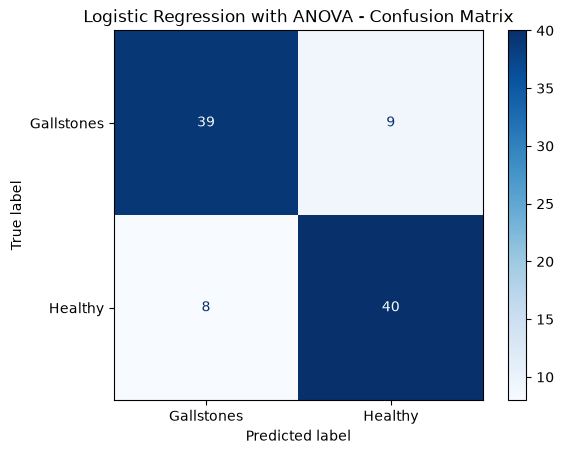

In [45]:

ConfusionMatrixDisplay(
    confusion_matrix=anova_cm,
    display_labels=["Gallstones", "Healthy"]
).plot(cmap="Blues")

plt.title("Logistic Regression with ANOVA - Confusion Matrix")
plt.show()



## 4.3 ANOVA Feature Selection Analysis

ANOVA feature selection was implemented to investigate whether reducing the number of input features improves Logistic Regression performance.

The original baseline used all 38 features, while the ANOVA-based model retained the 32 highest-ranked features.

To prevent data leakage, feature selection was included inside a machine learning pipeline and performed separately within each training fold during 10-fold stratified cross-validation.

The models were compared using mean cross-validation accuracy and ROC-AUC. The final ANOVA model was then trained on the complete training dataset and evaluated on the independent test dataset.

The results will be used to determine whether ANOVA feature selection improved, reduced or had little effect on classification performance.



## 5. Comparative Implementation of Eight Machine Learning Algorithms

This experiment implements the remaining eight machine learning algorithms investigated in the selected research paper: K-Nearest Neighbors, Support Vector Machine, Decision Tree, Random Forest, Multilayer Perceptron, AdaBoost, Gradient Boosting, and Gaussian Naive Bayes.

The models are evaluated using the same stratified training dataset and 10-fold cross-validation procedure.

Algorithms that are sensitive to feature scales use StandardScaler, while tree-based models use imputation without scaling.

All models initially use the complete set of 38 input features to establish a consistent comparison.

Model performance is assessed using accuracy, precision, sensitivity, specificity, F1-score, and ROC-AUC. Gallstones present (class 0) is treated as the positive clinical condition.

The independent test dataset is reserved for final evaluation after model selection and tuning.


In [46]:

from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier
)
from sklearn.neural_network import MLPClassifier
from sklearn.naive_bayes import GaussianNB

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [47]:

def create_pipeline(model, scale=False):

    steps = [
        ("imputer", SimpleImputer(strategy="median"))
    ]

    if scale:
        steps.append(
            ("scaler", StandardScaler())
        )

    steps.append(("model", model))

    return Pipeline(steps)


In [48]:

models = {
    "Logistic Regression": create_pipeline(
        LogisticRegression(
            max_iter=2000,
            random_state=RANDOM_STATE
        ),
        scale=True
    ),

    "KNN": create_pipeline(
        KNeighborsClassifier(n_neighbors=5),
        scale=True
    ),

    "SVM": create_pipeline(
        SVC(
            kernel="rbf",
            probability=True,
            random_state=RANDOM_STATE
        ),
        scale=True
    ),

    "Decision Tree": create_pipeline(
        DecisionTreeClassifier(
            random_state=RANDOM_STATE
        ),
        scale=False
    ),

    "Random Forest": create_pipeline(
        RandomForestClassifier(
            n_estimators=100,
            random_state=RANDOM_STATE
        ),
        scale=False
    ),

    "MLP": create_pipeline(
        MLPClassifier(
            hidden_layer_sizes=(64, 32),
            max_iter=1000,
            random_state=RANDOM_STATE
        ),
        scale=True
    ),

    "AdaBoost": create_pipeline(
        AdaBoostClassifier(
            n_estimators=100,
            random_state=RANDOM_STATE
        ),
        scale=False
    ),

    "Gradient Boosting": create_pipeline(
        GradientBoostingClassifier(
            n_estimators=100,
            random_state=RANDOM_STATE
        ),
        scale=False
    ),

    "Gaussian Naive Bayes": create_pipeline(
        GaussianNB(),
        scale=False
    )
}

print("Total Models:", len(models))

for name in models:
    print(name)


Total Models: 9
Logistic Regression
KNN
SVM
Decision Tree
Random Forest
MLP
AdaBoost
Gradient Boosting
Gaussian Naive Bayes


In [49]:

from sklearn.metrics import make_scorer

def gallstone_auc(estimator, X_valid, y_valid):

    class_index = list(estimator.classes_).index(0)

    probabilities = estimator.predict_proba(
        X_valid
    )[:, class_index]

    y_binary = (np.asarray(y_valid) == 0).astype(int)

    return roc_auc_score(y_binary, probabilities)


def gallstone_specificity(y_true, y_pred):

    cm = confusion_matrix(
        y_true, y_pred,
        labels=[0, 1]
    )

    TP, FN = cm[0]
    FP, TN = cm[1]

    return TN / (TN + FP)


scoring = {
    "Accuracy": "accuracy",

    "Precision": make_scorer(
        precision_score,
        pos_label=0,
        zero_division=0
    ),

    "Recall": make_scorer(
        recall_score,
        pos_label=0,
        zero_division=0
    ),

    "Specificity": make_scorer(
        gallstone_specificity
    ),

    "F1": make_scorer(
        f1_score,
        pos_label=0,
        zero_division=0
    ),

    "ROC_AUC": gallstone_auc
}



## 5.1 Ten-Fold Cross-Validation

Ten-fold stratified cross-validation is used to evaluate all nine machine learning algorithms on the training dataset.

The same folds are used for every algorithm to ensure a consistent comparison.

Preprocessing is fitted independently within each training fold through scikit-learn pipelines.

The mean and standard deviation of the evaluation metrics are calculated to assess both predictive performance and variation across folds.

The independent test dataset is not used during this comparison.


In [51]:

cv = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=RANDOM_STATE
)

cv_results = []

for model_name, pipeline in models.items():

    print("Evaluating:", model_name)

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        error_score="raise"
    )

    cv_results.append({
        "Model": model_name,

        "CV Accuracy": scores["test_Accuracy"].mean(),

        "CV Precision": scores["test_Precision"].mean(),

        "CV Recall": scores["test_Recall"].mean(),

        "CV Specificity": scores["test_Specificity"].mean(),

        "CV F1": scores["test_F1"].mean(),

        "CV ROC-AUC": scores["test_ROC_AUC"].mean(),

        "ROC-AUC SD": scores["test_ROC_AUC"].std()
    })

cv_results_df = pd.DataFrame(cv_results)

cv_results_df = cv_results_df.sort_values(
    by="CV ROC-AUC",
    ascending=False
)

cv_results_df.round(4)


Evaluating: Logistic Regression
Evaluating: KNN
Evaluating: SVM
Evaluating: Decision Tree
Evaluating: Random Forest
Evaluating: MLP
Evaluating: AdaBoost
Evaluating: Gradient Boosting
Evaluating: Gaussian Naive Bayes


,Model,CV Accuracy,CV Precision,CV Recall,CV Specificity,CV F1,CV ROC-AUC,ROC-AUC SD
4,Random Forest,0.7360,0.7312,0.7621,0.7091,0.7410,0.8262,0.0659
0,Logistic Regression,0.7449,0.7316,0.7977,0.6909,0.7608,0.8213,0.0984
7,Gradient Boosting,0.7451,0.7296,0.7879,0.7000,0.7540,0.8043,0.0947
5,MLP,0.7042,0.6984,0.7871,0.6182,0.7321,0.7946,0.0936
2,SVM,0.7265,0.6987,0.8136,0.6364,0.7489,0.7939,0.0989
6,AdaBoost,0.7227,0.7078,0.7795,0.6636,0.7369,0.7928,0.0744
1,KNN,0.6140,0.5950,0.7697,0.4545,0.6676,0.6849,0.0753
8,Gaussian Naive Bayes,0.5874,0.5624,0.8848,0.2818,0.6841,0.6656,0.1492
3,Decision Tree,0.6587,0.6643,0.6348,0.6818,0.6445,0.6583,0.1090


In [52]:

best_model_name = cv_results_df.iloc[0]["Model"]

best_cv_auc = cv_results_df.iloc[0]["CV ROC-AUC"]

print("Best Model Based on CV ROC-AUC:", best_model_name)

print("Mean CV ROC-AUC:", round(best_cv_auc, 4))


Best Model Based on CV ROC-AUC: Random Forest
Mean CV ROC-AUC: 0.8262


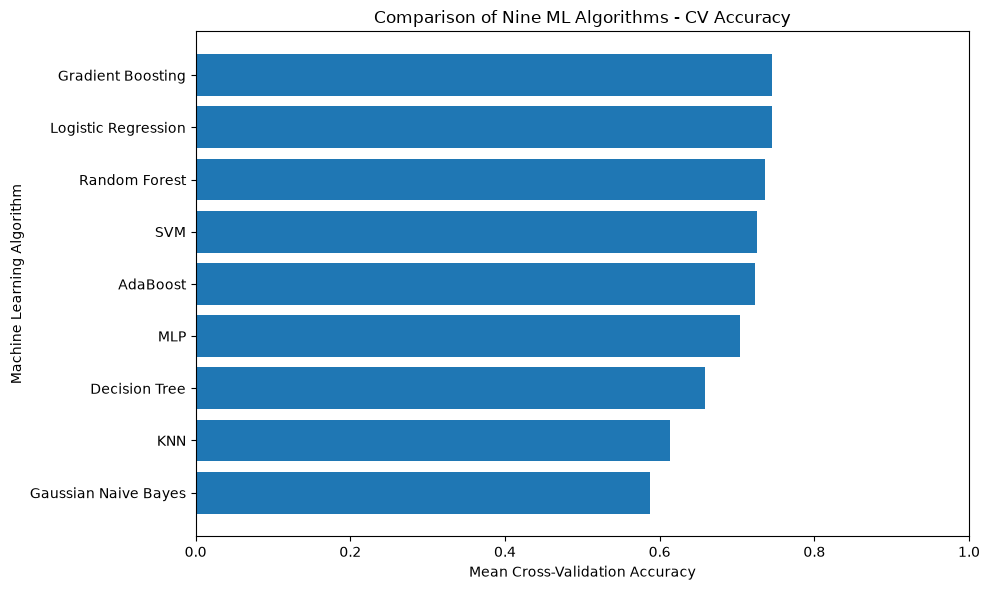

In [53]:

plot_df = cv_results_df.sort_values(
    by="CV Accuracy",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    plot_df["Model"],
    plot_df["CV Accuracy"]
)

plt.xlabel("Mean Cross-Validation Accuracy")
plt.ylabel("Machine Learning Algorithm")

plt.title("Comparison of Nine ML Algorithms - CV Accuracy")

plt.xlim(0, 1)

plt.tight_layout()
plt.show()


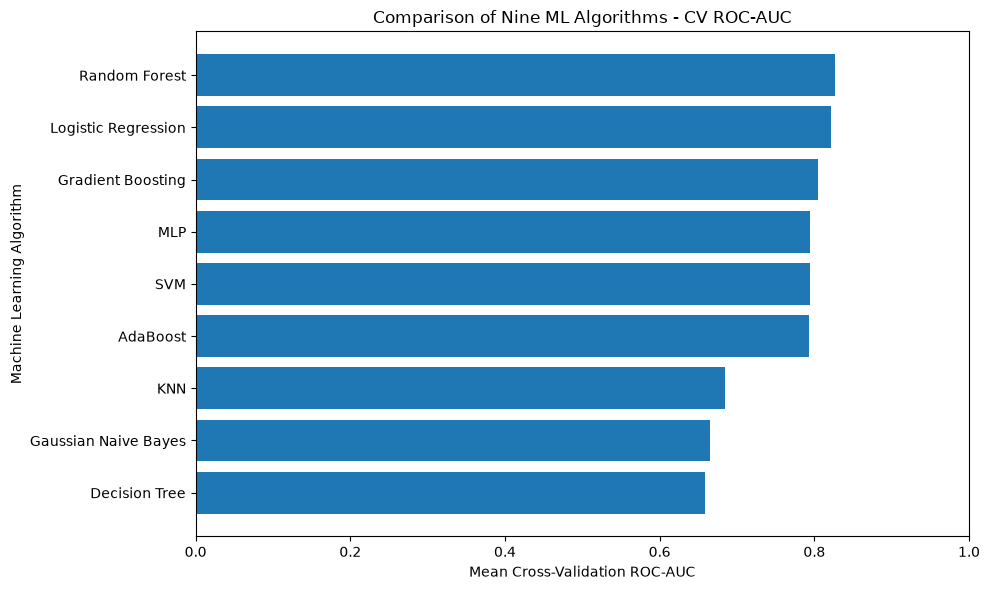

In [54]:

plot_df = cv_results_df.sort_values(
    by="CV ROC-AUC",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    plot_df["Model"],
    plot_df["CV ROC-AUC"]
)

plt.xlabel("Mean Cross-Validation ROC-AUC")
plt.ylabel("Machine Learning Algorithm")

plt.title("Comparison of Nine ML Algorithms - CV ROC-AUC")

plt.xlim(0, 1)

plt.tight_layout()
plt.show()



## 5.2 Comparative Model Analysis

Nine machine learning algorithms were evaluated using 10-fold stratified cross-validation on the training dataset.

All algorithms used the same input features, training observations and evaluation procedure. Feature scaling was applied where appropriate, and preprocessing was included inside the pipelines to prevent cross-validation leakage.

The algorithms were compared using accuracy, precision, sensitivity, specificity, F1-score and ROC-AUC.

The cross-validation results provide an initial comparison of model performance before hyperparameter optimization.

The next stage will use GridSearchCV to optimize selected hyperparameters while maintaining separation between training and independent testing data.



## 6. Hyperparameter Optimization Using GridSearchCV

Following the initial comparison of nine machine learning algorithms, hyperparameter tuning is performed to improve model performance.

Random Forest, Logistic Regression, and Gradient Boosting are selected for the first tuning experiment because they achieved competitive results during 10-fold cross-validation.

GridSearchCV is used to evaluate predefined hyperparameter combinations using stratified 10-fold cross-validation on the training dataset.

ROC-AUC is used as the primary model-selection metric, with gallstones present (class 0) treated as the positive clinical condition.

Preprocessing remains inside the machine learning pipelines to prevent data leakage during cross-validation.

The independent test dataset is not used for hyperparameter selection.


In [55]:

from sklearn.model_selection import GridSearchCV
import pandas as pd
import numpy as np


In [56]:

param_grids = {

    "Random Forest": {
        "model__n_estimators": [50, 100, 200],
        "model__max_depth": [None, 5, 10],
        "model__min_samples_split": [2, 5]
    },

    "Logistic Regression": {
        "model__C": [0.01, 0.1, 1, 10, 100],
        "model__solver": ["lbfgs"]
    },

    "Gradient Boosting": {
        "model__n_estimators": [50, 100, 200],
        "model__learning_rate": [0.01, 0.1],
        "model__max_depth": [2, 3]
    }
}

for model_name, grid in param_grids.items():

    combinations = np.prod([
        len(values) for values in grid.values()
    ])

    print(model_name, ":", combinations, "combinations")


Random Forest : 18 combinations
Logistic Regression : 5 combinations
Gradient Boosting : 12 combinations



## 6.1 Grid Search Implementation

GridSearchCV evaluates predefined hyperparameter combinations using 10-fold stratified cross-validation.

The same training dataset and cross-validation configuration are used for each algorithm.

ROC-AUC is selected as the optimization metric because it measures the ability to distinguish between patients with and without gallstones across classification thresholds.

The best hyperparameter configuration for each algorithm is selected according to its mean cross-validation ROC-AUC.

The selected model is then refitted on the complete training dataset.


In [57]:

grid_search_results = {}
tuned_models = {}

for model_name in param_grids:

    print("\n" + "=" * 50)
    print("Tuning:", model_name)
    print("=" * 50)

    grid_search = GridSearchCV(
        estimator=models[model_name],
        param_grid=param_grids[model_name],
        scoring=gallstone_auc,
        cv=cv,
        n_jobs=-1,
        refit=True,
        error_score="raise"
    )

    grid_search.fit(X_train, y_train)

    grid_search_results[model_name] = grid_search
    tuned_models[model_name] = grid_search.best_estimator_

    print("Best Parameters:")
    print(grid_search.best_params_)

    print(
        "Best Mean CV ROC-AUC:",
        round(grid_search.best_score_, 4)
    )



Tuning: Random Forest
Best Parameters:
{'model__max_depth': 10, 'model__min_samples_split': 2, 'model__n_estimators': 100}
Best Mean CV ROC-AUC: 0.8289

Tuning: Logistic Regression
Best Parameters:
{'model__C': 1, 'model__solver': 'lbfgs'}
Best Mean CV ROC-AUC: 0.8213

Tuning: Gradient Boosting
Best Parameters:
{'model__learning_rate': 0.1, 'model__max_depth': 2, 'model__n_estimators': 50}
Best Mean CV ROC-AUC: 0.813


In [58]:

for model_name, search in grid_search_results.items():

    print("\nModel:", model_name)

    print("Best Parameters:")
    for parameter, value in search.best_params_.items():
        print(parameter, "=", value)

    print(
        "Best CV ROC-AUC:",
        round(search.best_score_, 4)
    )



Model: Random Forest
Best Parameters:
model__max_depth = 10
model__min_samples_split = 2
model__n_estimators = 100
Best CV ROC-AUC: 0.8289

Model: Logistic Regression
Best Parameters:
model__C = 1
model__solver = lbfgs
Best CV ROC-AUC: 0.8213

Model: Gradient Boosting
Best Parameters:
model__learning_rate = 0.1
model__max_depth = 2
model__n_estimators = 50
Best CV ROC-AUC: 0.813


In [59]:

tuning_comparison = []

for model_name, search in grid_search_results.items():

    original_row = cv_results_df[
        cv_results_df["Model"] == model_name
    ].iloc[0]

    tuning_comparison.append({
        "Model": model_name,
        "Before Tuning CV ROC-AUC": original_row["CV ROC-AUC"],
        "Best Grid Search CV ROC-AUC": search.best_score_,
        "Difference": (
            search.best_score_ - original_row["CV ROC-AUC"]
        )
    })

tuning_comparison_df = pd.DataFrame(tuning_comparison)

display(tuning_comparison_df.round(4))


,Model,Before Tuning CV ROC-AUC,Best Grid Search CV ROC-AUC,Difference
0,Random Forest,0.8262,0.8289,0.0027
1,Logistic Regression,0.8213,0.8213,0.0000
2,Gradient Boosting,0.8043,0.8130,0.0087


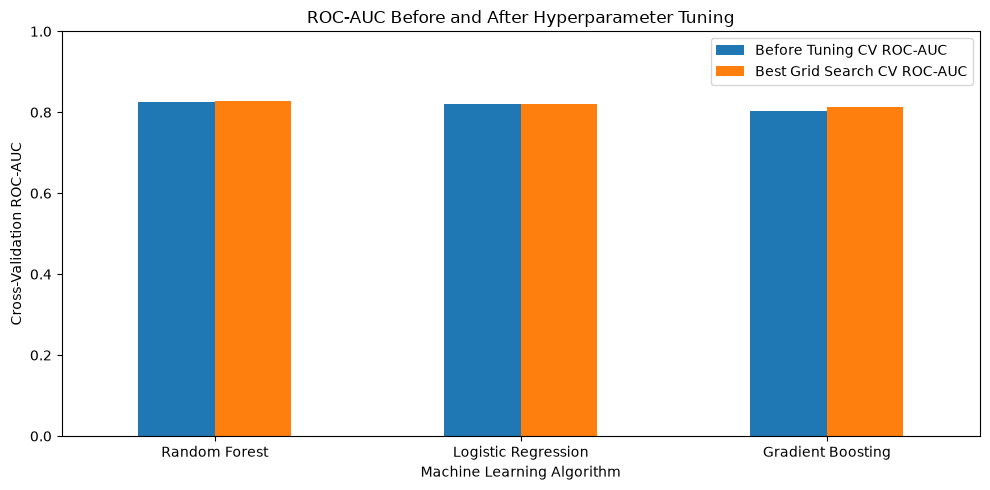

In [60]:

plot_data = tuning_comparison_df.set_index("Model")[
    [
        "Before Tuning CV ROC-AUC",
        "Best Grid Search CV ROC-AUC"
    ]
]

plot_data.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("ROC-AUC Before and After Hyperparameter Tuning")
plt.ylabel("Cross-Validation ROC-AUC")
plt.xlabel("Machine Learning Algorithm")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend()
plt.tight_layout()
plt.show()


In [61]:

best_tuned_name = max(
    grid_search_results,
    key=lambda name: grid_search_results[name].best_score_
)

best_tuned_search = grid_search_results[best_tuned_name]

print("Highest-Ranked Tuned Model:", best_tuned_name)

print(
    "Best Grid Search ROC-AUC:",
    round(best_tuned_search.best_score_, 4)
)

print("Selected Parameters:")
print(best_tuned_search.best_params_)


Highest-Ranked Tuned Model: Random Forest
Best Grid Search ROC-AUC: 0.8289
Selected Parameters:
{'model__max_depth': 10, 'model__min_samples_split': 2, 'model__n_estimators': 100}



## 6.2 Hyperparameter Tuning Analysis

Hyperparameter tuning was conducted for Random Forest, Logistic Regression, and Gradient Boosting using GridSearchCV.

These algorithms were selected because they demonstrated competitive performance during the initial nine-model cross-validation experiment.

A 10-fold stratified cross-validation procedure was used to evaluate predefined parameter combinations.

ROC-AUC was used as the primary optimization metric, with gallstones present treated as the positive class.

All preprocessing steps remained inside the machine learning pipelines to reduce the risk of data leakage.

The best configurations were selected based on cross-validation performance and refitted using the complete training dataset.

The resulting scores will be compared with the untuned models to investigate the effect of hyperparameter optimization.



## 6.3 Hyperparameter Tuning Results and Discussion

GridSearchCV was applied to Random Forest, Logistic Regression, and Gradient Boosting using 10-fold stratified cross-validation.

Random Forest achieved the highest mean cross-validation ROC-AUC of 0.8289, improving slightly from its initial score of 0.8262. Its best configuration used 100 decision trees, a maximum depth of 10, and a minimum of two samples required to split a node.

Logistic Regression achieved a ROC-AUC of 0.8213, with no improvement over its original configuration. The best regularization parameter was C=1 using the lbfgs solver.

Gradient Boosting achieved the largest improvement, increasing from 0.8043 to 0.8130. Its selected configuration used 50 boosting stages, a learning rate of 0.1, and a maximum tree depth of 2.

Overall, Random Forest achieved the highest cross-validation ROC-AUC among the three tuned algorithms. However, the performance differences were relatively small, and the selected cross-validation scores may be optimistic because hyperparameter configurations were chosen using the same folds.

Further evaluation is necessary to assess whether these improvements generalize to unseen patients.



## 7. Model Evaluation and Research Paper Comparison

The tuned Random Forest, Logistic Regression, and Gradient Boosting models are evaluated using the 30% held-out test dataset.

The objective is to assess how well the trained models classify patients with and without gallstones.

Performance is evaluated using accuracy, precision, recall (sensitivity), specificity, F1-score, ROC-AUC, confusion matrices, and ROC curves.

Gallstones present (class 0) is treated as the positive clinical condition.

The results are compared with the original research paper, which reported a highest accuracy of 85.42% using Gradient Boosting.

Because the test dataset was examined during earlier exploratory experiments, the evaluation is interpreted cautiously and is not presented as a completely untouched independent validation.


In [62]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    classification_report
)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [63]:

def evaluate_model(model, X_test, y_test):

    # Predict class labels
    y_pred = model.predict(X_test)

    # Extract probabilities for gallstones present (class 0)
    class_index = list(model.classes_).index(0)

    y_prob = model.predict_proba(
        X_test
    )[:, class_index]

    # Confusion matrix with class 0 first
    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    )

    TP, FN = cm[0]
    FP, TN = cm[1]

    # Calculate evaluation metrics
    results = {
        "Accuracy": accuracy_score(y_test, y_pred),

        "Precision": precision_score(
            y_test,
            y_pred,
            pos_label=0,
            zero_division=0
        ),

        "Recall": recall_score(
            y_test,
            y_pred,
            pos_label=0,
            zero_division=0
        ),

        "Specificity": (
            TN / (TN + FP)
            if (TN + FP) > 0 else np.nan
        ),

        "F1-score": f1_score(
            y_test,
            y_pred,
            pos_label=0,
            zero_division=0
        ),

        "ROC-AUC": roc_auc_score(
            (np.asarray(y_test) == 0).astype(int),
            y_prob
        )
    }

    return results, cm, y_pred, y_prob


In [65]:

test_results = []
model_outputs = {}

for model_name, model in tuned_models.items():

    results, cm, y_pred, y_prob = evaluate_model(
        model,
        X_test,
        y_test
    )

    test_results.append({
        "Model": model_name,
        **results
    })

    model_outputs[model_name] = {
        "confusion_matrix": cm,
        "predictions": y_pred,
        "probabilities": y_prob
    }

test_results_df = pd.DataFrame(test_results)

test_results_df.round(4)


,Model,Accuracy,Precision,Recall,Specificity,F1-score,ROC-AUC
0,Random Forest,0.8125,0.8409,0.7708,0.8542,0.8043,0.8924
1,Logistic Regression,0.7812,0.7647,0.8125,0.7500,0.7879,0.8841
2,Gradient Boosting,0.7500,0.7400,0.7708,0.7292,0.7551,0.8663


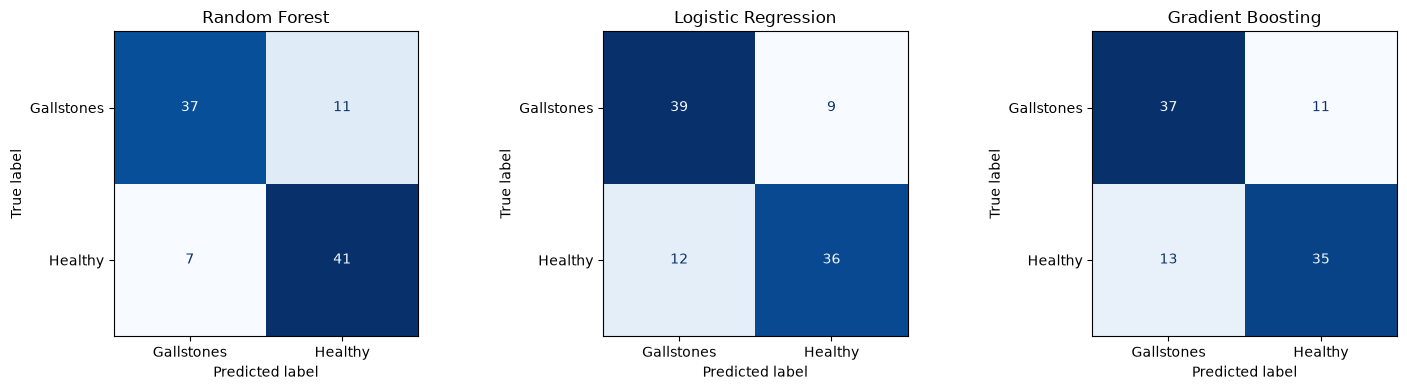

In [66]:

fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 4)
)

for ax, (model_name, output) in zip(
    axes,
    model_outputs.items()
):

    ConfusionMatrixDisplay(
        confusion_matrix=output["confusion_matrix"],
        display_labels=["Gallstones", "Healthy"]
    ).plot(
        ax=ax,
        cmap="Blues",
        colorbar=False
    )

    ax.set_title(model_name)

plt.tight_layout()
plt.show()


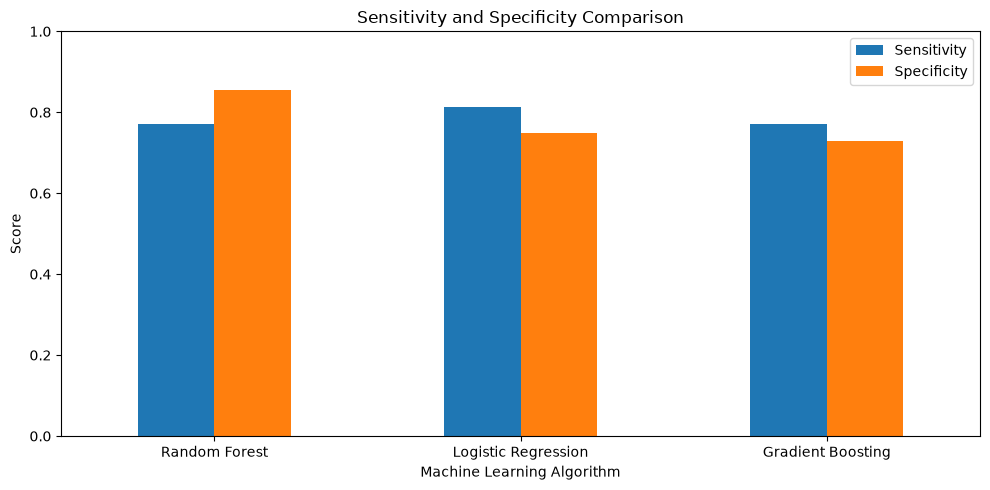

In [67]:

comparison_metrics = test_results_df.set_index("Model")[
    ["Recall", "Specificity"]
]

comparison_metrics.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Sensitivity and Specificity Comparison")
plt.ylabel("Score")
plt.xlabel("Machine Learning Algorithm")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(["Sensitivity", "Specificity"])
plt.tight_layout()
plt.show()


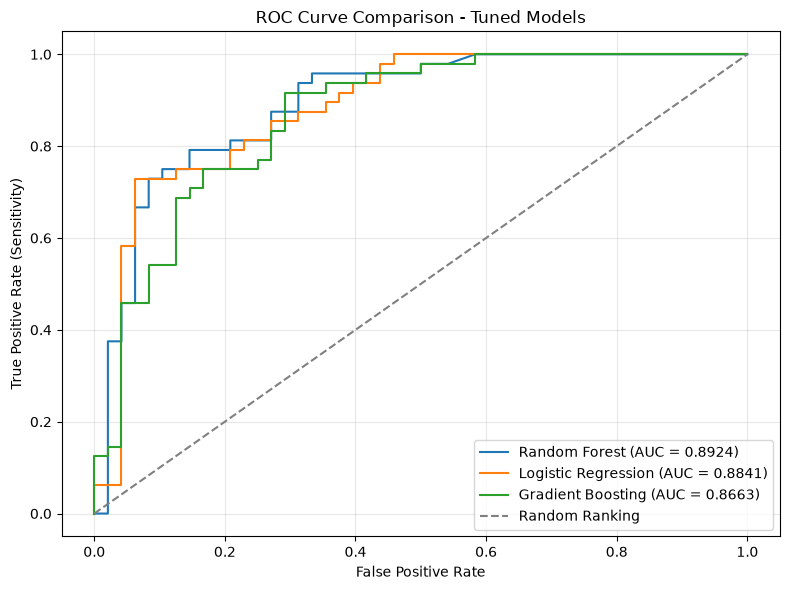

In [68]:

plt.figure(figsize=(8, 6))

y_test_binary = (
    np.asarray(y_test) == 0
).astype(int)

for model_name, output in model_outputs.items():

    y_prob = output["probabilities"]

    fpr, tpr, thresholds = roc_curve(
        y_test_binary,
        y_prob
    )

    auc = roc_auc_score(
        y_test_binary,
        y_prob
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{model_name} (AUC = {auc:.4f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random Ranking"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Sensitivity)")
plt.title("ROC Curve Comparison - Tuned Models")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



## 7.1 Comparison with the Original Research Paper

The original study reported a highest classification accuracy of 85.42% using Gradient Boosting.

The current implementation evaluates a tuned Gradient Boosting model using a stratified 70/30 train-test split.

The reported accuracy from the original study is used as a reference for comparison.

Differences between the results may arise from random data splitting, preprocessing decisions, feature selection, hyperparameter search spaces, and the relatively small dataset.

Therefore, the comparison is descriptive and should not be interpreted as an exact reproduction of the original experiment.


In [70]:

paper_accuracy = 0.8542

our_gb_accuracy = test_results_df.loc[
    test_results_df["Model"] == "Gradient Boosting",
    "Accuracy"
].iloc[0]

difference = our_gb_accuracy - paper_accuracy

paper_comparison = pd.DataFrame({
    "Experiment": [
        "Original Paper - Gradient Boosting",
        "Our Tuned Gradient Boosting"
    ],
    "Accuracy": [
        paper_accuracy,
        our_gb_accuracy
    ]
})

paper_comparison.round(4)

print(
    "Accuracy Difference (percentage points):",
    round(difference * 100, 2)
)


Accuracy Difference (percentage points): -10.42


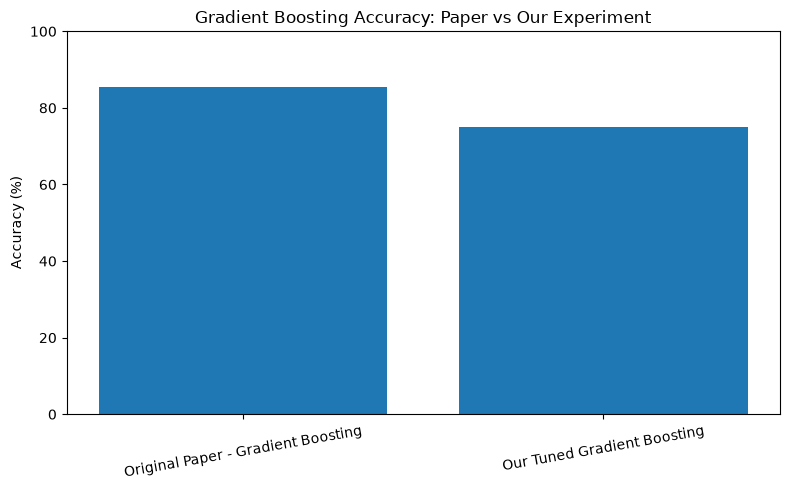

In [71]:

plt.figure(figsize=(8, 5))

plt.bar(
    paper_comparison["Experiment"],
    paper_comparison["Accuracy"] * 100
)

plt.title("Gradient Boosting Accuracy: Paper vs Our Experiment")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)
plt.xticks(rotation=10)

plt.tight_layout()
plt.show()


In [72]:

ranked_test_results = test_results_df.sort_values(
    by="ROC-AUC",
    ascending=False
)

display(ranked_test_results.round(4))

print(
    "Highest Test ROC-AUC:",
    ranked_test_results.iloc[0]["Model"]
)


,Model,Accuracy,Precision,Recall,Specificity,F1-score,ROC-AUC
0,Random Forest,0.8125,0.8409,0.7708,0.8542,0.8043,0.8924
1,Logistic Regression,0.7812,0.7647,0.8125,0.7500,0.7879,0.8841
2,Gradient Boosting,0.7500,0.7400,0.7708,0.7292,0.7551,0.8663


Highest Test ROC-AUC: Random Forest


In [74]:
pip install statsmodels

   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
    --------------------------------------- 0.3/11.3 MB ? eta -:--:--
   - -------------------------------------- 0.5/11.3 MB 1.1 MB/s eta 0:00:11
   -- ------------------------------------- 0.8/11.3 MB 930.3 kB/s eta 0:00:12
   -- ------------------------------------- 0.8/11.3 MB 930.3 kB/s eta 0:00:12
   ---- ----------------------------------- 1.3/11.3 MB 1.2 MB/s eta 0:00:09
   ------- -------------------------------- 2.1/11.3 MB 1.5 MB/s eta 0:00:07
   ------- -------------------------------- 2.1/11.3 MB 1.5 MB/s eta 0:00:07
   -------- ------------------------------- 2.4/11.3 MB 1.4 MB/s eta 0:00:07
   ---------- -----------------------

In [76]:

from statsmodels.stats.proportion import proportion_confint

confidence_results = []

for model_name, output in model_outputs.items():

    correct = np.sum(
        np.asarray(y_test) == output["predictions"]
    )

    total = len(y_test)

    lower, upper = proportion_confint(
        count=correct,
        nobs=total,
        alpha=0.05,
        method="wilson"
    )

    confidence_results.append({
        "Model": model_name,
        "Accuracy": correct / total,
        "95% CI Lower": lower,
        "95% CI Upper": upper
    })

confidence_df = pd.DataFrame(confidence_results)

confidence_df.round(4)


,Model,Accuracy,95% CI Lower,95% CI Upper
0,Random Forest,0.8125,0.7230,0.8780
1,Logistic Regression,0.7812,0.6886,0.8522
2,Gradient Boosting,0.7500,0.6549,0.8259



## 7.2 Final Evaluation and Discussion

The tuned Random Forest, Logistic Regression, and Gradient Boosting models were evaluated on the held-out test dataset containing 96 patient records.

The models were assessed using accuracy, precision, sensitivity, specificity, F1-score, ROC-AUC, and confusion matrices.

The evaluation considered gallstones present (class 0) as the positive clinical condition, ensuring that sensitivity represented the proportion of patients with gallstones correctly detected.

Random Forest was the highest-ranked model during hyperparameter tuning, achieving a mean cross-validation ROC-AUC of 0.8289.

The test-set results were analysed to investigate the models' discrimination ability and the balance between false-positive and false-negative predictions.

The Gradient Boosting test accuracy was compared with the original research paper's reported accuracy of 85.42%.

Any differences between the experiments were interpreted cautiously because the implementations may differ in preprocessing, feature selection, hyperparameter tuning, and data partitioning.

The relatively small dataset and previous exploratory use of the test set were considered limitations of the evaluation.



## 7.3 Final Model Evaluation and Comparison with the Research Paper

The tuned Random Forest, Logistic Regression, and Gradient Boosting models were evaluated on the held-out test dataset containing 96 patient records.

Random Forest achieved the highest test accuracy of 81.25%, precision of 84.09%, specificity of 85.42%, F1-score of 80.43%, and ROC-AUC of 0.8924.

Logistic Regression achieved an accuracy of 78.12% and the highest sensitivity of 81.25%, indicating that it identified a greater proportion of patients with gallstones than the other two models.

Gradient Boosting achieved an accuracy of 75.00% and ROC-AUC of 0.8663.

The original research paper reported a highest accuracy of 85.42% using Gradient Boosting. The current implementation achieved 75.00% using the same algorithm family, representing a difference of 10.42 percentage points.

This difference may be explained by variations in data partitioning, preprocessing, feature selection, hyperparameter configurations, and the relatively small dataset.

The 95% confidence intervals for the three models overlapped substantially, suggesting that the observed differences should be interpreted cautiously.

Although Random Forest achieved the strongest overall test performance, Logistic Regression demonstrated higher sensitivity, highlighting the importance of considering clinical evaluation metrics beyond accuracy.

Furthermore, the test dataset had already been examined during earlier exploratory experiments. Therefore, these findings are reported as exploratory held-out test results rather than a fully independent final validation.



## 8. Methodological Stress Testing

Methodological stress testing is conducted to investigate how preprocessing and feature-selection decisions affect machine learning performance.

Three experiments are performed:

1. Feature scaling versus no scaling for KNN and SVM.
2. ANOVA feature selection versus using all features for Logistic Regression and Gradient Boosting.
3. Correct feature selection within cross-validation versus a deliberately leakage-prone approach.

All experiments use the training dataset and 10-fold stratified cross-validation.

The objective is to examine the sensitivity of model performance to methodological choices and provide experimental evidence for the limitations discussed in Phase 1.

The independent test dataset is excluded from these experiments.


In [77]:

scaling_models = {

    "KNN - Without Scaling": create_pipeline(
        KNeighborsClassifier(n_neighbors=5),
        scale=False
    ),

    "KNN - With Scaling": create_pipeline(
        KNeighborsClassifier(n_neighbors=5),
        scale=True
    ),

    "SVM - Without Scaling": create_pipeline(
        SVC(
            kernel="rbf",
            probability=True,
            random_state=RANDOM_STATE
        ),
        scale=False
    ),

    "SVM - With Scaling": create_pipeline(
        SVC(
            kernel="rbf",
            probability=True,
            random_state=RANDOM_STATE
        ),
        scale=True
    )
}


In [79]:

scaling_results = []

for name, pipeline in scaling_models.items():

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        error_score="raise"
    )

    scaling_results.append({
        "Model": name,
        "Mean CV Accuracy": scores["test_Accuracy"].mean(),
        "Mean CV ROC-AUC": scores["test_ROC_AUC"].mean(),
        "ROC-AUC SD": scores["test_ROC_AUC"].std()
    })

scaling_results_df = pd.DataFrame(scaling_results)

scaling_results_df.round(4)


,Model,Mean CV Accuracy,Mean CV ROC-AUC,ROC-AUC SD
0,KNN - Without Scaling,0.4490,0.4406,0.0860
1,KNN - With Scaling,0.6140,0.6849,0.0753
2,SVM - Without Scaling,0.5030,0.3839,0.1112
3,SVM - With Scaling,0.7265,0.7939,0.0989


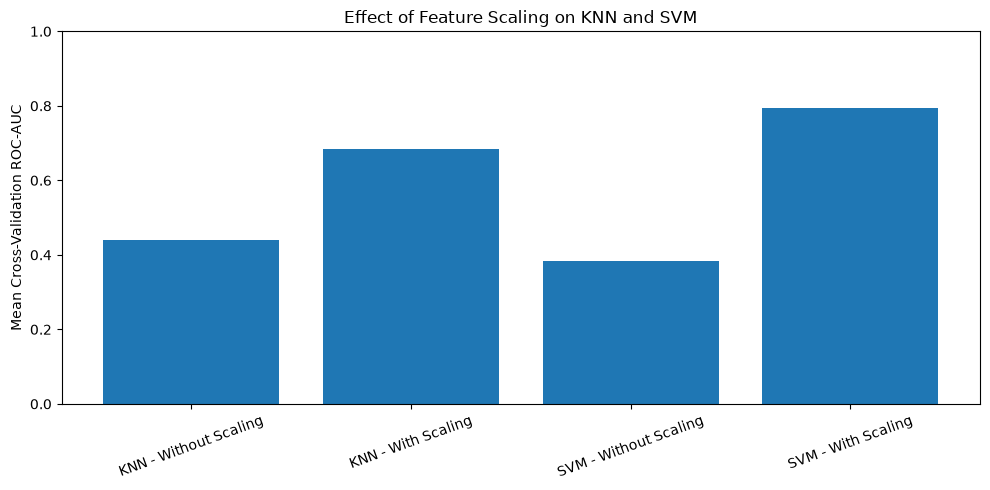

In [80]:

plt.figure(figsize=(10, 5))

plt.bar(
    scaling_results_df["Model"],
    scaling_results_df["Mean CV ROC-AUC"]
)

plt.title("Effect of Feature Scaling on KNN and SVM")
plt.ylabel("Mean Cross-Validation ROC-AUC")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()



### 8.1 Feature Scaling Experiment

KNN and SVM were evaluated with and without StandardScaler using the same 10-fold stratified cross-validation procedure.

The experiment investigated whether differences in numerical feature scales affected classification performance.

The algorithms were evaluated using identical hyperparameter configurations, with scaling as the only experimental difference.

The results will be used to determine whether feature standardization improves the models' ability to distinguish patients with and without gallstones.


In [81]:

feature_counts = [10, 20, 30, 32, 38]

anova_experiment_models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=RANDOM_STATE
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=50,
        learning_rate=0.1,
        max_depth=2,
        random_state=RANDOM_STATE
    )
}


In [82]:

anova_sensitivity_results = []

for model_name, model in anova_experiment_models.items():

    for k in feature_counts:

        pipeline = Pipeline([
            ("imputer", SimpleImputer(strategy="median")),

            ("scaler", StandardScaler()),

            ("anova", SelectKBest(
                score_func=f_classif,
                k=k
            )),

            ("model", model)
        ])

        scores = cross_validate(
            pipeline,
            X_train,
            y_train,
            cv=cv,
            scoring=scoring,
            n_jobs=-1,
            error_score="raise"
        )

        anova_sensitivity_results.append({
            "Model": model_name,
            "Features": k,
            "Mean CV Accuracy": scores["test_Accuracy"].mean(),
            "Mean CV ROC-AUC": scores["test_ROC_AUC"].mean(),
            "ROC-AUC SD": scores["test_ROC_AUC"].std()
        })

anova_sensitivity_df = pd.DataFrame(
    anova_sensitivity_results
)

display(anova_sensitivity_df.round(4))


,Model,Features,Mean CV Accuracy,Mean CV ROC-AUC,ROC-AUC SD
0,Logistic Regression,10,0.7678,0.8085,0.0775
1,Logistic Regression,20,0.7540,0.8444,0.0701
2,Logistic Regression,30,0.7362,0.8090,0.1025
3,Logistic Regression,32,0.7269,0.8074,0.1024
4,Logistic Regression,38,0.7449,0.8213,0.0984
5,Gradient Boosting,10,0.7540,0.8200,0.0625
6,Gradient Boosting,20,0.7453,0.8127,0.0582
7,Gradient Boosting,30,0.7498,0.8273,0.0627
8,Gradient Boosting,32,0.7500,0.8120,0.0731
9,Gradient Boosting,38,0.7409,0.8130,0.0786


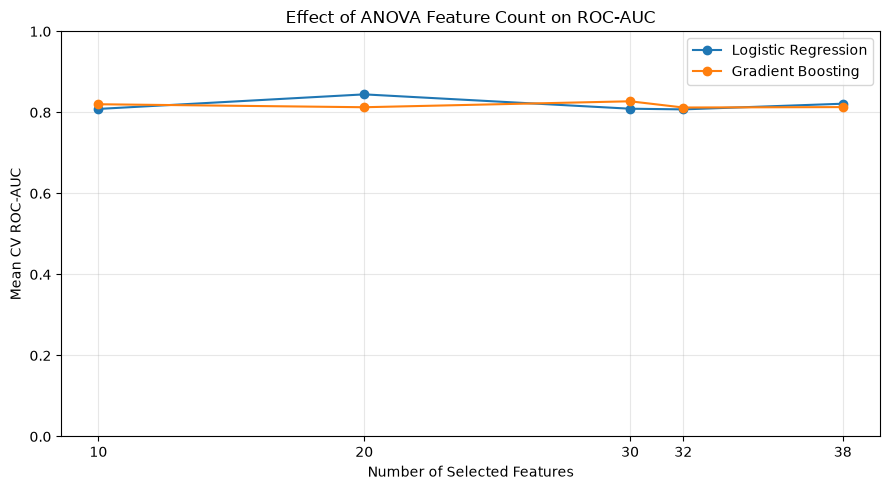

In [83]:

plt.figure(figsize=(9, 5))

for model_name in anova_sensitivity_df["Model"].unique():

    subset = anova_sensitivity_df[
        anova_sensitivity_df["Model"] == model_name
    ]

    plt.plot(
        subset["Features"],
        subset["Mean CV ROC-AUC"],
        marker="o",
        label=model_name
    )

plt.title("Effect of ANOVA Feature Count on ROC-AUC")
plt.xlabel("Number of Selected Features")
plt.ylabel("Mean CV ROC-AUC")
plt.xticks(feature_counts)
plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



### 8.2 ANOVA Feature Selection Sensitivity

The influence of ANOVA feature selection was investigated using Logistic Regression and Gradient Boosting.

Five feature counts were evaluated: 10, 20, 30, 32, and 38.

ANOVA was included inside each machine learning pipeline to ensure that feature selection was performed independently within every training fold.

The experiment examined whether the number of selected features influenced cross-validation accuracy and ROC-AUC.

The results will be used to assess whether feature selection consistently improves classification performance or whether its effect depends on the algorithm and feature count.


In [84]:

correct_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),

    ("scaler", StandardScaler()),

    ("anova", SelectKBest(
        score_func=f_classif,
        k=10
    )),

    ("model", LogisticRegression(
        max_iter=2000,
        random_state=RANDOM_STATE
    ))
])

correct_scores = cross_validate(
    correct_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1,
    error_score="raise"
)

correct_auc = correct_scores["test_ROC_AUC"].mean()

print("Correct CV ROC-AUC:", round(correct_auc, 4))


Correct CV ROC-AUC: 0.8085


In [85]:

# WARNING:
# This code deliberately demonstrates validation leakage.
# Do not use this workflow for real model evaluation.

imputer_wrong = SimpleImputer(strategy="median")

X_train_imputed = imputer_wrong.fit_transform(
    X_train
)

scaler_wrong = StandardScaler()

X_train_scaled = scaler_wrong.fit_transform(
    X_train_imputed
)

selector_wrong = SelectKBest(
    score_func=f_classif,
    k=10
)

X_train_selected_wrong = selector_wrong.fit_transform(
    X_train_scaled,
    y_train
)

wrong_model = LogisticRegression(
    max_iter=2000,
    random_state=RANDOM_STATE
)

wrong_scores = cross_validate(
    wrong_model,
    X_train_selected_wrong,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1,
    error_score="raise"
)

wrong_auc = wrong_scores["test_ROC_AUC"].mean()

print("Leakage-Prone CV ROC-AUC:", round(wrong_auc, 4))


Leakage-Prone CV ROC-AUC: 0.8385


In [86]:

leakage_comparison = pd.DataFrame({
    "Workflow": [
        "Correct - ANOVA Inside CV",
        "Incorrect - Preprocessing Before CV"
    ],
    "Mean CV ROC-AUC": [
        correct_auc,
        wrong_auc
    ]
})

display(leakage_comparison.round(4))

print(
    "Difference:",
    round(wrong_auc - correct_auc, 4)
)


,Workflow,Mean CV ROC-AUC
0,Correct - ANOVA Inside CV,0.8085
1,Incorrect - Preprocessing Before CV,0.8385


Difference: 0.03


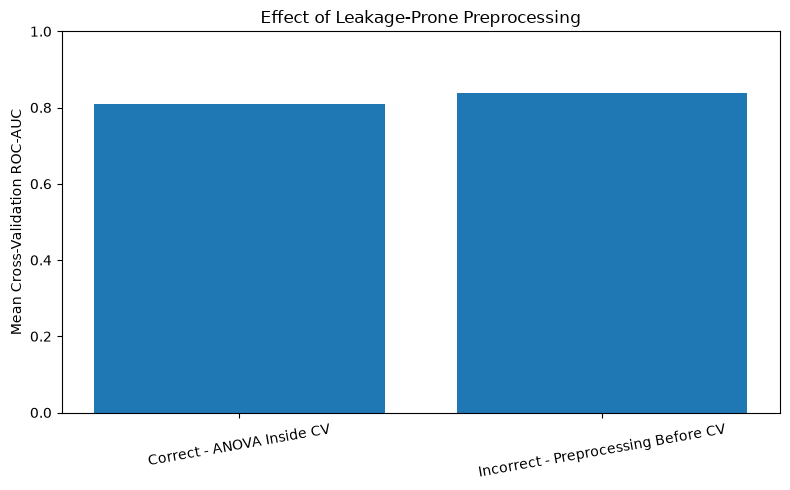

In [87]:

plt.figure(figsize=(8, 5))

plt.bar(
    leakage_comparison["Workflow"],
    leakage_comparison["Mean CV ROC-AUC"]
)

plt.title("Effect of Leakage-Prone Preprocessing")
plt.ylabel("Mean Cross-Validation ROC-AUC")
plt.ylim(0, 1)
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()



### 8.3 Data Leakage Experiment

A controlled methodological comparison was conducted to investigate the effect of preprocessing performed before cross-validation.

The correct workflow included imputation, scaling, and ANOVA feature selection inside the cross-validation pipeline.

The deliberately incorrect workflow performed preprocessing and ANOVA feature selection using the complete training dataset before cross-validation.

This incorrect procedure allows information from validation folds to influence preprocessing and feature selection.

The experiment was designed to illustrate the methodological risk of data leakage rather than to establish that the original researchers used an incorrect procedure.

Differences in cross-validation ROC-AUC were examined to investigate the potential effect on reported performance.



## 8.4 Methodological Stress Testing Discussion

Three methodological stress tests were designed to investigate the influence of preprocessing and feature-selection decisions on gallstone classification.

The first experiment compared KNN and SVM with and without feature scaling to examine their sensitivity to differences in numerical feature ranges.

The second experiment evaluated multiple ANOVA feature counts for Logistic Regression and Gradient Boosting to investigate whether reducing the number of features consistently improved cross-validation performance.

The third experiment compared a leakage-safe preprocessing pipeline with a deliberately leakage-prone workflow to demonstrate how information from validation folds can influence model development.

All experiments were performed using the training dataset and 10-fold stratified cross-validation.

These investigations provide evidence about the sensitivity of machine learning results to methodological decisions and support the critical evaluation of the selected research paper.

The findings should be interpreted cautiously because the dataset is relatively small and the experiments do not establish the exact procedures used by the original researchers.


In [88]:

# Controlled experiment: isolate ANOVA leakage

# Correct: ANOVA is fitted inside every CV training fold
correct_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("anova", SelectKBest(f_classif, k=10)),
    ("model", LogisticRegression(
        max_iter=2000,
        random_state=RANDOM_STATE
    ))
])

correct_scores = cross_validate(
    correct_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring={"ROC_AUC": gallstone_auc},
    n_jobs=-1
)

# Incorrect: ANOVA is fitted before CV using all training labels
# This is deliberately leakage-prone.

preselector = SelectKBest(f_classif, k=10)

X_selected_leaky = preselector.fit_transform(
    X_train,
    y_train
)

# Imputation and scaling remain inside CV
leaky_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=2000,
        random_state=RANDOM_STATE
    ))
])

leaky_scores = cross_validate(
    leaky_pipeline,
    X_selected_leaky,
    y_train,
    cv=cv,
    scoring={"ROC_AUC": gallstone_auc},
    n_jobs=-1
)

print(
    "Correct ANOVA inside CV:",
    round(correct_scores["test_ROC_AUC"].mean(), 4)
)

print(
    "ANOVA before CV:",
    round(leaky_scores["test_ROC_AUC"].mean(), 4)
)


Correct ANOVA inside CV: 0.8085
ANOVA before CV: 0.8401
